# 🧠 Notebook 06 — RQ3: Single-Modality Deep Learning (ICG-Only)

---

> **RQ3:** Can the temporal deep learning model (LSTM/CNN-LSTM) on raw ICG data outperform the conventional ML model in terms of prediction accuracy?

## Architecture
```
Input: ICG dZ/dt window  (B, 1, 200)     ← matches actual window length, no padding
  │
  ├── Conv1d(1→32,  k=7, padding=3) + BatchNorm + ReLU + MaxPool
  ├── Conv1d(32→64, k=5, padding=2) + BatchNorm + ReLU + MaxPool
  └── Conv1d(64→128,k=3, padding=1) + BatchNorm + ReLU
                    ↓
          BiLSTM(128 hidden, 2 layers)
                    ↓
          Global Average Pooling
                    ↓
          FC(256→128) + ReLU + Dropout(0.3)
          FC(128→2)   → [PEP_pred, LVET_pred]
```

## Training
- **Loss:** Huber Loss (robust to outliers, specified in methodology)
- **Optimizer:** AdamW with cosine annealing LR schedule
- **Validation:** LOSO cross-validation — one subject reserved as a fixed dev
  set for early stopping, the rest rotate as outer test folds (see below)
- **Device:** GPU (CUDA) if available, fallback to CPU

---
**Requires:** `./output/final_dataset/` from Notebook 03

In [1]:
FINAL_DATASET_DIR = './output/final_dataset'
RESULTS_DIR       = './output/results/rq3_single_modality'

import os
os.makedirs(f'{RESULTS_DIR}/figures', exist_ok=True)
os.makedirs(f'{RESULTS_DIR}/checkpoints', exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, warnings, time
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})


# ── GPU Setup ──
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps'  if torch.backends.mps.is_available() else 'cpu')
print(f'🖥️  Device: {device}')
if device.type == 'cuda':
    print(f'   GPU: {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')


np.random.seed(42)
torch.manual_seed(42)
if device.type == 'cuda':
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True


# Hyperparameters
HP = {
    'T':           200,       # fixed window length (samples) — matches Notebook
                               # 02/03's WIN_SAMPLES; overridden below from the
                               # actual data shape as a safety check
    'batch_size':  64,
    'epochs':      100,
    'lr':          1e-3,
    'weight_decay':1e-4,
    'huber_delta': 10.0,      # ms — Huber loss delta
    'dropout':     0.3,
    'lstm_hidden': 128,
    'lstm_layers': 2,
}

print(f'\nHyperparameters: {HP}')

🖥️  Device: cpu

Hyperparameters: {'T': 200, 'batch_size': 64, 'epochs': 100, 'lr': 0.001, 'weight_decay': 0.0001, 'huber_delta': 10.0, 'dropout': 0.3, 'lstm_hidden': 128, 'lstm_layers': 2}


## 1. Dataset — Fixed-Length Windows (T=200 samples, matches Notebook 02/03)

In [3]:
class HeartCycleDataset(Dataset):
    """
    PyTorch Dataset for HeartCycle beat windows.
    Pads/truncates to fixed length T (200 samples — matches the actual window
    length from Notebook 02/03, so this is a no-op for the current pipeline).
    Supports single-modality (ICG or ECG) and multimodal (ICG+ECG).
    """

    def __init__(self, X, y_pep, y_lvet, T=200, mode='icg'):
        """
        X:     (N, C, orig_len) or (N, orig_len)  — signal windows
        y_pep: (N,)  — PEP ground truth in ms
        y_lvet:(N,)  — LVET ground truth in ms
        T:     fixed output length (pad/truncate)
        mode:  'icg', 'ecg', or 'multi' (for channel handling)
        """
        self.T    = T
        self.mode = mode

        # Handle shape: (N, orig_len) → (N, 1, orig_len)
        if X.ndim == 2:
            X = X[:, np.newaxis, :]   # add channel dim
        # Now X is (N, C, orig_len)

        # Pad or truncate to T
        orig_len = X.shape[2]
        if orig_len < T:
            pad = np.zeros((X.shape[0], X.shape[1], T - orig_len), dtype=np.float32)
            X = np.concatenate([X, pad], axis=2)
        elif orig_len > T:
            X = X[:, :, :T]

        self.X     = torch.tensor(X,      dtype=torch.float32)
        self.y_pep  = torch.tensor(y_pep,  dtype=torch.float32)
        self.y_lvet = torch.tensor(y_lvet, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            torch.stack([self.y_pep[idx], self.y_lvet[idx]])
        )


def load_split_arrays(split_dir):
    """Load all arrays for a split."""
    d = Path(split_dir)
    return {
        'X_icg':  np.load(d / 'X_icg.npy'),
        'X_ecg':  np.load(d / 'X_ecg.npy'),
        'X_multi':np.load(d / 'X_multi.npy'),
        'y_pep':  np.load(d / 'y_pep.npy'),
        'y_lvet': np.load(d / 'y_lvet.npy'),
        'meta':   pd.read_csv(d / 'meta.csv'),
    }

base = Path(FINAL_DATASET_DIR)
train_data = load_split_arrays(base / 'train')
val_data   = load_split_arrays(base / 'val')
test_data  = load_split_arrays(base / 'test')


# Combine train+val for LOSO
X_icg_all  = np.concatenate([train_data['X_icg'],  val_data['X_icg']],  axis=0)
y_pep_all  = np.concatenate([train_data['y_pep'],  val_data['y_pep']],  axis=0)
y_lvet_all = np.concatenate([train_data['y_lvet'], val_data['y_lvet']], axis=0)
meta_all   = pd.concat([train_data['meta'], val_data['meta']], ignore_index=True)
subjects   = meta_all['subject_id'].values
unique_subj = np.unique(subjects)

# HP['T'] was 256 in the proposal's original Ri-to-Ri+1 padding scheme, which
# Notebook 02 moved away from — every beat window here is exactly WIN_SAMPLES=200
# samples. Pin T to the real length rather than zero-pad 56 samples (28% of the
# sequence) of pure zeros onto every window for no benefit.
HP['T'] = X_icg_all.shape[-1]
print(f"HP['T'] set to actual window length: {HP['T']} samples (no padding)")

print(f'Total beats (LOSO pool): {len(X_icg_all):,}')
print(f'ICG window shape:        {X_icg_all.shape}  (matches HP["T"]={HP["T"]}, no padding needed)')
print(f'Subjects for LOSO:       {len(unique_subj)}')

# Verify dataset class
test_ds = HeartCycleDataset(X_icg_all[:10], y_pep_all[:10], y_lvet_all[:10], T=HP['T'])
x_, y_ = test_ds[0]
print(f'\nDataset test — X shape: {x_.shape}, y shape: {y_.shape}')

HP['T'] set to actual window length: 200 samples (no padding)
Total beats (LOSO pool): 210
ICG window shape:        (210, 200)  (matches HP["T"]=200, no padding needed)
Subjects for LOSO:       11

Dataset test — X shape: torch.Size([1, 200]), y shape: torch.Size([2])


In [4]:
# ── Reserve a fixed dev subject for early stopping (NOT a rotating inner-split) ──
# Bug being fixed: early stopping previously picked "best epoch" by evaluating on
# the fold's own TEST subject (evaluate(model, test_loader, ...) inside the epoch
# loop). The model never backprops on the test subject, but choosing WHICH epoch
# to report by peeking at test performance is still leakage — it lets the model
# opportunistically catch a lucky epoch per test subject, silently inflating every
# LOSO number. Fix: one subject is permanently reserved as a fixed development set
# — never a test subject, never in any fold's training data — and early stopping
# is decided on that subject alone. A rotating inner-split was considered and
# rejected: it would put tiny subjects (e.g. CHC06's 6 beats) into the dev role for
# some folds, making early stopping nearly meaningless there.
#
# Counts shift after upstream preprocessing changes, so recheck before picking:
print(pd.Series(subjects).value_counts())

DEV_SUBJECT = 'CHC14'  # largest subject as of this run (44 beats) — adjust if the
                        # counts above show a different subject is now largest.
loso_test_subjects = [s for s in unique_subj if s != DEV_SUBJECT]

print(f'\nDev subject (early-stopping only; never trained or tested on as a fold): '
      f'{DEV_SUBJECT} ({(subjects == DEV_SUBJECT).sum()} beats)')
print(f'LOSO test subjects ({len(loso_test_subjects)}): {loso_test_subjects}')
print('Note: this costs one fewer outer fold (10 instead of 11) — a reasonable '
      'trade for validity given how small this dataset is.')

CHC14    44
CHC10    33
CHC07    22
CHC12    22
CHC02    18
CHC05    18
CHC09    17
CHC04    13
CHC01     9
CHC08     8
CHC06     6
Name: count, dtype: int64

Dev subject (early-stopping only; never trained or tested on as a fold): CHC14 (44 beats)
LOSO test subjects (10): ['CHC01', 'CHC02', 'CHC04', 'CHC05', 'CHC06', 'CHC07', 'CHC08', 'CHC09', 'CHC10', 'CHC12']
Note: this costs one fewer outer fold (10 instead of 11) — a reasonable trade for validity given how small this dataset is.


## 2. CNN-LSTM Architecture

In [5]:
class ConvBlock1D(nn.Module):
    """Conv1d + BatchNorm + ReLU + MaxPool block."""
    def __init__(self, in_ch, out_ch, kernel_size, pool=True):
        super().__init__()
        pad = kernel_size // 2
        layers = [
            nn.Conv1d(in_ch, out_ch, kernel_size, padding=pad, bias=False),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if pool:
            layers.append(nn.MaxPool1d(2))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class CNNLSTM(nn.Module):
    """
    CNN-LSTM model for single-modality ICG (or ECG) regression.

    Architecture (from methodology Section 6.4A):
    - 3 × 1D convolutional blocks (32→64→128 filters)
    - Bidirectional LSTM (128 hidden, 2 layers)
    - Global average pooling
    - FC regression head → [PEP, LVET]
    """

    def __init__(self, in_channels=1, T=200,
                 lstm_hidden=128, lstm_layers=2, dropout=0.3):
        super().__init__()

        # ── CNN Encoder ──
        self.cnn = nn.Sequential(
            ConvBlock1D(in_channels, 32,  kernel_size=7, pool=True),  # T/2
            ConvBlock1D(32,          64,  kernel_size=5, pool=True),  # T/4
            ConvBlock1D(64,          128, kernel_size=3, pool=False),  # stays T/4
        )
        # After CNN: (B, 128, T//4)

        # ── Bidirectional LSTM ──
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=lstm_hidden,
            num_layers=lstm_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if lstm_layers > 1 else 0.0,
        )
        lstm_out_size = lstm_hidden * 2  # bidirectional

        # ── Regression Head ──
        self.head = nn.Sequential(
            nn.Linear(lstm_out_size, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(128, 2),   # [PEP, LVET]
        )

        self._init_weights()


    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None: nn.init.zeros_(m.bias)


    def forward(self, x):
        # x: (B, C, T)
        feat = self.cnn(x)                 # (B, 128, T//4)
        feat = feat.permute(0, 2, 1)       # (B, T//4, 128) — LSTM expects (B, seq, features)
        lstm_out, _ = self.lstm(feat)      # (B, T//4, 256)
        pooled = lstm_out.mean(dim=1)      # (B, 256) — global average pooling
        out = self.head(pooled)            # (B, 2)
        return out


# ── Test architecture ──
dummy = torch.zeros(4, 1, HP['T'])
model_test = CNNLSTM(in_channels=1, T=HP['T'],
                     lstm_hidden=HP['lstm_hidden'],
                     lstm_layers=HP['lstm_layers'],
                     dropout=HP['dropout'])
out_test = model_test(dummy)
n_params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)

print('CNN-LSTM Architecture:')
print(model_test)
print(f'\nInput:  {dummy.shape}')
print(f'Output: {out_test.shape}  → [PEP_pred, LVET_pred]')
print(f'Trainable parameters: {n_params:,}')

CNN-LSTM Architecture:
CNNLSTM(
  (cnn): Sequential(
    (0): ConvBlock1D(
      (block): Sequential(
        (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock1D(
      (block): Sequential(
        (0): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
        (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock1D(
      (block): Sequential(
        (0): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
        (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=Tru

## 3. Training Utilities

In [6]:
def train_one_epoch(model, loader, optimizer, loss_fn, device):
    model.train()
    total_loss = 0.0
    all_preds, all_true = [], []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)  # faster than zero_grad()
        preds = model(X_batch)
        loss  = loss_fn(preds, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # gradient clipping
        optimizer.step()

        total_loss += loss.item() * len(X_batch)
        all_preds.append(preds.detach().cpu().numpy())
        all_true.append(y_batch.detach().cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_true  = np.concatenate(all_true)
    mae_pep   = mean_absolute_error(all_true[:,0], all_preds[:,0])
    mae_lvet  = mean_absolute_error(all_true[:,1], all_preds[:,1])
    return total_loss / len(loader.dataset), mae_pep, mae_lvet


@torch.no_grad()
def evaluate(model, loader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_true = [], []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)
        preds   = model(X_batch)
        loss    = loss_fn(preds, y_batch)
        total_loss += loss.item() * len(X_batch)
        all_preds.append(preds.cpu().numpy())
        all_true.append(y_batch.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_true  = np.concatenate(all_true)
    mae_pep   = mean_absolute_error(all_true[:,0], all_preds[:,0])
    mae_lvet  = mean_absolute_error(all_true[:,1], all_preds[:,1])
    return total_loss / len(loader.dataset), mae_pep, mae_lvet, all_preds, all_true


def compute_full_metrics(all_true, all_preds, prefix=''):
    """Compute all evaluation metrics for both targets."""
    results = {}
    for i, name in enumerate(['PEP', 'LVET']):
        t = all_true[:,i]; p = all_preds[:,i]
        results[f'{prefix}{name}_MAE']       = mean_absolute_error(t, p)
        results[f'{prefix}{name}_RMSE']      = np.sqrt(mean_squared_error(t, p))
        results[f'{prefix}{name}_R2']        = r2_score(t, p)
        results[f'{prefix}{name}_within7ms'] = np.mean(np.abs(p-t) < 7)  * 100
        results[f'{prefix}{name}_within15ms']= np.mean(np.abs(p-t) < 15) * 100
    return results

print('Training utilities ready.')

Training utilities ready.


## 4. LOSO Training Loop

In [7]:
def run_loso_cnnlstm(X_signal, y_pep, y_lvet, subjects, HP, device,
                     model_name='CNN-LSTM', in_channels=1, save_dir=None,
                     dev_subject=None):
    """
    Full LOSO cross-validation for CNN-LSTM.

    If dev_subject is given, that subject is permanently reserved as a fixed
    development set for early-stopping model selection: it is never used as a
    test subject and never included in any fold's training data. (Selecting the
    "best epoch" by evaluating on the fold's own test subject is test-set leakage
    — the model never backprops on it, but peeking at its performance to choose
    which epoch to report still lets the model opportunistically catch a lucky
    epoch, inflating every LOSO number.) If dev_subject is None, early stopping
    falls back to the test subject itself — leaky, kept only for quick debugging.

    Returns per-fold results and aggregated metrics.
    """

    unique_subj = np.unique(subjects)
    test_subjects = [s for s in unique_subj if s != dev_subject] if dev_subject is not None else list(unique_subj)
    loss_fn = nn.HuberLoss(delta=HP['huber_delta'])
    fold_results = []
    all_preds_loso = np.zeros((len(y_pep), 2))
    all_true_loso  = np.zeros((len(y_pep), 2))
    fold_histories = []

    # Fixed dev set for early stopping — built once, identical across every fold.
    dev_loader = None
    if dev_subject is not None:
        dev_mask = (subjects == dev_subject)
        dev_ds = HeartCycleDataset(X_signal[dev_mask], y_pep[dev_mask], y_lvet[dev_mask], T=HP['T'])
        dev_loader = DataLoader(dev_ds, batch_size=HP['batch_size']*2,
                                shuffle=False, num_workers=0, pin_memory=(device.type=='cuda'))
    else:
        print('  ⚠️  No dev_subject given — early stopping will use the TEST subject '
              'itself. This is test-set leakage; only use for quick debugging.')

    for fold_i, test_subj in enumerate(test_subjects):
        print(f'\n  Fold {fold_i+1}/{len(test_subjects)} — Test subject: {test_subj}')
        test_mask  = (subjects == test_subj)
        train_mask = ~test_mask
        if dev_subject is not None:
            train_mask &= (subjects != dev_subject)  # dev subject never trained on

        X_tr = X_signal[train_mask]; y_pep_tr = y_pep[train_mask]; y_lvet_tr = y_lvet[train_mask]
        X_te = X_signal[test_mask];  y_pep_te = y_pep[test_mask];  y_lvet_te = y_lvet[test_mask]

        train_ds = HeartCycleDataset(X_tr, y_pep_tr, y_lvet_tr, T=HP['T'])
        test_ds  = HeartCycleDataset(X_te, y_pep_te, y_lvet_te, T=HP['T'])

        train_loader = DataLoader(train_ds, batch_size=HP['batch_size'],
                                  shuffle=True,  num_workers=0, pin_memory=(device.type=='cuda'))
        test_loader  = DataLoader(test_ds,  batch_size=HP['batch_size']*2,
                                  shuffle=False, num_workers=0, pin_memory=(device.type=='cuda'))
        # Early-stopping loader: the fixed dev subject when reserved, else the
        # test subject itself (only reachable when dev_subject is None).
        es_loader = dev_loader if dev_loader is not None else test_loader

        model = CNNLSTM(in_channels=in_channels, T=HP['T'],
                        lstm_hidden=HP['lstm_hidden'],
                        lstm_layers=HP['lstm_layers'],
                        dropout=HP['dropout']).to(device)

        optimizer = AdamW(model.parameters(), lr=HP['lr'], weight_decay=HP['weight_decay'])
        scheduler = CosineAnnealingLR(optimizer, T_max=HP['epochs'], eta_min=1e-5)

        best_val_mae = float('inf')
        best_state   = None
        best_epoch   = None
        patience_cnt = 0
        patience_max = 20
        history = {'train_loss': [], 'dev_mae_pep': [], 'dev_mae_lvet': []}

        t0 = time.time()
        for epoch in range(HP['epochs']):
            tr_loss, tr_mae_pep, tr_mae_lvet = train_one_epoch(model, train_loader, optimizer, loss_fn, device)
            dev_loss, dev_mae_pep, dev_mae_lvet, _, _ = evaluate(model, es_loader, loss_fn, device)
            scheduler.step()

            history['train_loss'].append(tr_loss)
            history['dev_mae_pep'].append(dev_mae_pep)
            history['dev_mae_lvet'].append(dev_mae_lvet)

            avg_dev_mae = (dev_mae_pep + dev_mae_lvet) / 2
            if avg_dev_mae < best_val_mae:
                best_val_mae = avg_dev_mae
                best_state   = {k: v.clone() for k, v in model.state_dict().items()}
                best_epoch   = epoch + 1  # the epoch actually kept, by the same
                                           # criterion (avg PEP+LVET) that chose it —
                                           # not recomputed later from a single-target history
                patience_cnt = 0
            else:
                patience_cnt += 1
                if patience_cnt >= patience_max:
                    print(f'    Early stop at epoch {epoch+1}')
                    break

            if (epoch+1) % 20 == 0:
                elapsed = time.time() - t0
                print(f'    Epoch {epoch+1:3d}/{HP["epochs"]} | Loss:{tr_loss:.3f} | '
                      f'Dev PEP:{dev_mae_pep:.1f}ms | Dev LVET:{dev_mae_lvet:.1f}ms | '
                      f'Time:{elapsed:.0f}s')


        # Load the dev-selected best weights, then evaluate ONCE on the held-out
        # test subject — the test subject never influenced which epoch was kept.
        model.load_state_dict(best_state)
        _, _, _, preds, true_vals = evaluate(model, test_loader, loss_fn, device)

        all_preds_loso[test_mask] = preds
        all_true_loso[test_mask]  = true_vals

        metrics = compute_full_metrics(true_vals, preds)
        metrics['subject'] = test_subj
        metrics['n_test']  = test_mask.sum()
        metrics['best_epoch'] = best_epoch
        fold_results.append(metrics)
        fold_histories.append(history)

        print(f'    → Best: PEP MAE={metrics["PEP_MAE"]:.2f}ms | LVET MAE={metrics["LVET_MAE"]:.2f}ms')

        if save_dir:
            torch.save(best_state, f'{save_dir}/fold_{fold_i}_{test_subj}.pt')

    # The reserved dev subject's rows in all_preds_loso/all_true_loso are never
    # written (it's never a test subject) and stay at their zero initialization —
    # exclude them explicitly so they can't silently corrupt the aggregate metrics.
    agg_mask = (subjects != dev_subject) if dev_subject is not None else np.ones(len(y_pep), dtype=bool)

    fdf = pd.DataFrame(fold_results)
    agg_metrics = compute_full_metrics(all_true_loso[agg_mask], all_preds_loso[agg_mask], prefix='agg_')
    agg_metrics['model'] = model_name
    agg_metrics['dev_subject'] = dev_subject
    agg_metrics['loso_test_subjects'] = test_subjects

    return fdf, agg_metrics, all_preds_loso, all_true_loso, fold_histories

print('LOSO training function ready.')
print(f'Will train {len(loso_test_subjects)} models (one per fold; '
      f'{DEV_SUBJECT} reserved as fixed dev subject, never a fold)')
print(f'Each fold: {HP["epochs"]} epochs max, early stop patience=20')

LOSO training function ready.
Will train 10 models (one per fold; CHC14 reserved as fixed dev subject, never a fold)
Each fold: 100 epochs max, early stop patience=20


In [8]:
# ── RUN CNN-LSTM (ICG-only) ──
print('='*60)
print('TRAINING CNN-LSTM — ICG ONLY (RQ3)')
print('='*60)

cnnlstm_folds, cnnlstm_agg, cnnlstm_preds, cnnlstm_true, cnnlstm_hist = run_loso_cnnlstm(
    X_icg_all,    # ICG-only input (N, 200)
    y_pep_all, y_lvet_all, subjects, HP, device,
    model_name='CNN-LSTM (ICG-only)',
    in_channels=1,
    save_dir=f'{RESULTS_DIR}/checkpoints',
    dev_subject=DEV_SUBJECT,   # fixed early-stopping subject — never trained or tested on
)

print(f'\n=== CNN-LSTM (ICG-ONLY) — LOSO AGGREGATED RESULTS ===')
print(f'PEP:  MAE={cnnlstm_agg["agg_PEP_MAE"]:.2f}ms  |  RMSE={cnnlstm_agg["agg_PEP_RMSE"]:.2f}ms  |  R²={cnnlstm_agg["agg_PEP_R2"]:.3f}')
print(f'LVET: MAE={cnnlstm_agg["agg_LVET_MAE"]:.2f}ms  |  RMSE={cnnlstm_agg["agg_LVET_RMSE"]:.2f}ms  |  R²={cnnlstm_agg["agg_LVET_R2"]:.3f}')
print(f'PEP  within ±15ms: {cnnlstm_agg["agg_PEP_within15ms"]:.1f}%')
print(f'LVET within ±15ms: {cnnlstm_agg["agg_LVET_within15ms"]:.1f}%')

TRAINING CNN-LSTM — ICG ONLY (RQ3)

  Fold 1/10 — Test subject: CHC01


    Epoch  20/100 | Loss:192.599 | Dev PEP:10.9ms | Dev LVET:11.2ms | Time:9s


    Epoch  40/100 | Loss:173.546 | Dev PEP:12.2ms | Dev LVET:10.2ms | Time:18s


    Early stop at epoch 41
    → Best: PEP MAE=8.67ms | LVET MAE=4.44ms

  Fold 2/10 — Test subject: CHC02


    Epoch  20/100 | Loss:181.239 | Dev PEP:10.0ms | Dev LVET:11.9ms | Time:8s


...

    Epoch  20/100 | Loss:192.129 | Dev PEP:12.2ms | Dev LVET:9.7ms | Time:9s


    Early stop at epoch 32
    → Best: PEP MAE=9.47ms | LVET MAE=9.55ms

  Fold 10/10 — Test subject: CHC12


    Epoch  20/100 | Loss:171.179 | Dev PEP:10.6ms | Dev LVET:10.9ms | Time:10s


    Epoch  40/100 | Loss:155.043 | Dev PEP:15.7ms | Dev LVET:10.8ms | Time:21s


    Early stop at epoch 41
    → Best: PEP MAE=12.55ms | LVET MAE=44.42ms

=== CNN-LSTM (ICG-ONLY) — LOSO AGGREGATED RESULTS ===
PEP:  MAE=12.44ms  |  RMSE=13.83ms  |  R²=-0.625
LVET: MAE=25.12ms  |  RMSE=32.21ms  |  R²=-0.021
PEP  within ±15ms: 62.7%
LVET within ±15ms: 39.2%


## 5. Training Curves & Results Visualization

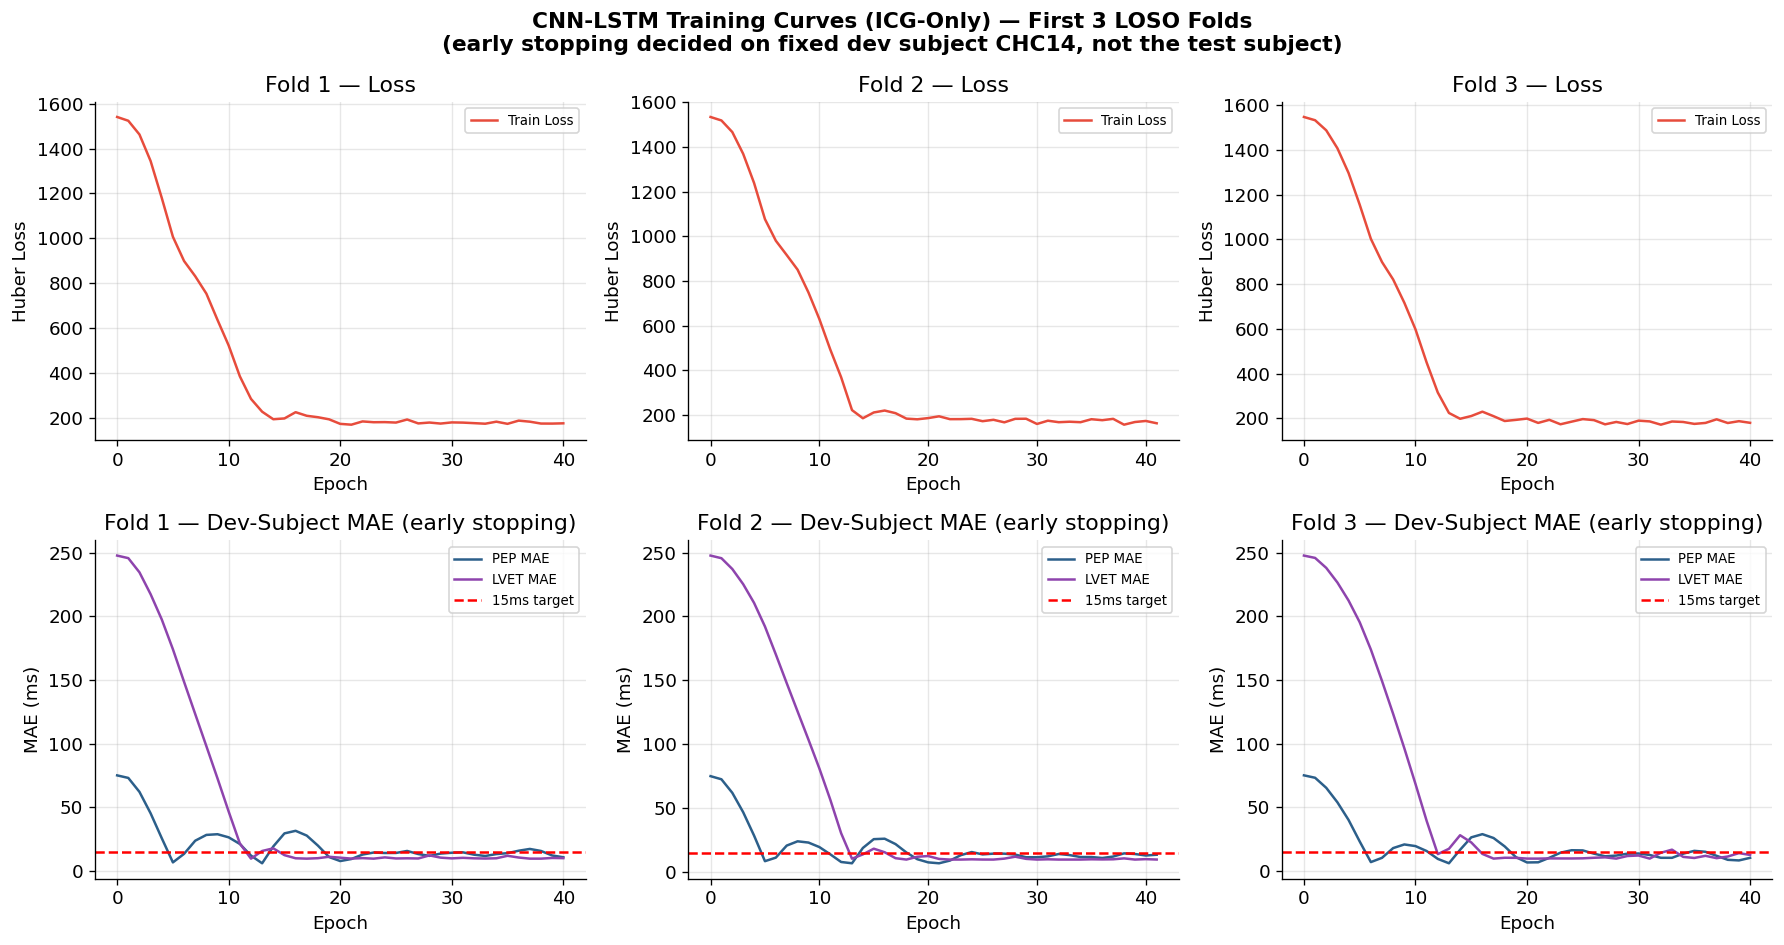

In [9]:
# Training curves — show first 3 folds
fig, axes = plt.subplots(2, min(3, len(cnnlstm_hist)), figsize=(15, 8))
fig.suptitle(f'CNN-LSTM Training Curves (ICG-Only) — First 3 LOSO Folds\n'
             f'(early stopping decided on fixed dev subject {DEV_SUBJECT}, not the test subject)',
             fontsize=13, fontweight='bold')

for col_i, hist in enumerate(cnnlstm_hist[:3]):
    axes[0, col_i].plot(hist['train_loss'], color='#E74C3C', linewidth=1.5, label='Train Loss')
    axes[0, col_i].set_title(f'Fold {col_i+1} — Loss')
    axes[0, col_i].set_xlabel('Epoch')
    axes[0, col_i].set_ylabel('Huber Loss')
    axes[0, col_i].legend(fontsize=8)

    axes[1, col_i].plot(hist['dev_mae_pep'],  color='#2C5F8A', linewidth=1.5, label='PEP MAE')
    axes[1, col_i].plot(hist['dev_mae_lvet'], color='#8E44AD', linewidth=1.5, label='LVET MAE')
    axes[1, col_i].axhline(15, color='red', linewidth=1.5, linestyle='--', label='15ms target')
    axes[1, col_i].set_title(f'Fold {col_i+1} — Dev-Subject MAE (early stopping)')
    axes[1, col_i].set_xlabel('Epoch')
    axes[1, col_i].set_ylabel('MAE (ms)')
    axes[1, col_i].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq3_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

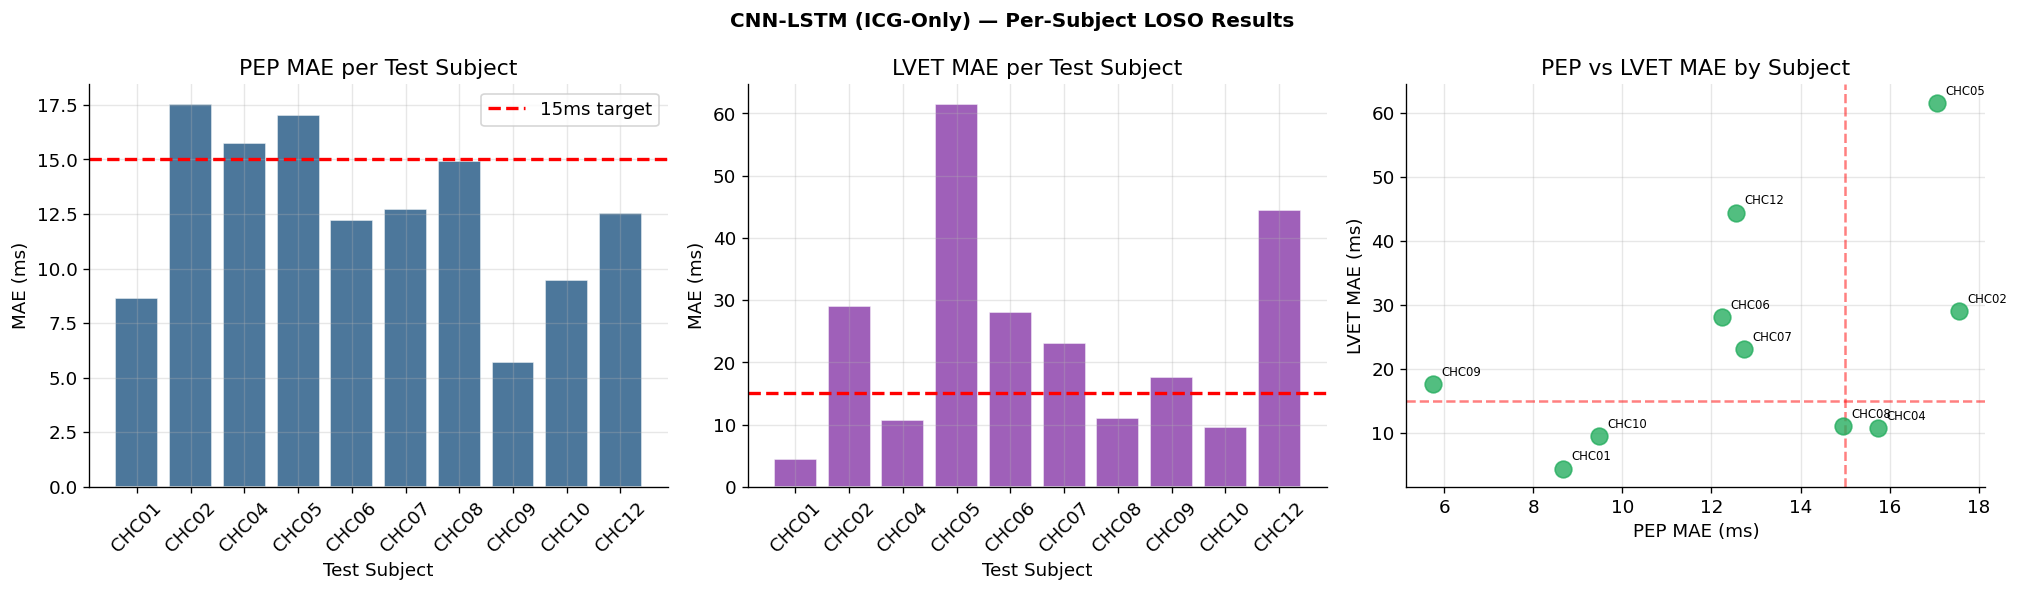

In [10]:
# Per-subject LOSO results
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('CNN-LSTM (ICG-Only) — Per-Subject LOSO Results', fontsize=12, fontweight='bold')

axes[0].bar(cnnlstm_folds['subject'], cnnlstm_folds['PEP_MAE'],
            color='#2C5F8A', alpha=0.85, edgecolor='white')
axes[0].axhline(15, color='red', linewidth=2, linestyle='--', label='15ms target')
axes[0].set_title('PEP MAE per Test Subject')
axes[0].set_xlabel('Test Subject')
axes[0].set_ylabel('MAE (ms)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

axes[1].bar(cnnlstm_folds['subject'], cnnlstm_folds['LVET_MAE'],
            color='#8E44AD', alpha=0.85, edgecolor='white')
axes[1].axhline(15, color='red', linewidth=2, linestyle='--')
axes[1].set_title('LVET MAE per Test Subject')
axes[1].set_xlabel('Test Subject')
axes[1].set_ylabel('MAE (ms)')
axes[1].tick_params(axis='x', rotation=45)

axes[2].scatter(cnnlstm_folds['PEP_MAE'], cnnlstm_folds['LVET_MAE'],
                s=100, c='#27AE60', alpha=0.8, zorder=5)
for _, row in cnnlstm_folds.iterrows():
    axes[2].annotate(row['subject'], (row['PEP_MAE'], row['LVET_MAE']),
                     textcoords='offset points', xytext=(5,5), fontsize=7)
axes[2].set_xlabel('PEP MAE (ms)')
axes[2].set_ylabel('LVET MAE (ms)')
axes[2].set_title('PEP vs LVET MAE by Subject')
axes[2].axvline(15, color='red', linewidth=1.5, linestyle='--', alpha=0.5)
axes[2].axhline(15, color='red', linewidth=1.5, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq3_per_subject_results.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
cnnlstm_folds.to_csv(f'{RESULTS_DIR}/cnnlstm_loso_fold_results.csv', index=False)

with open(f'{RESULTS_DIR}/cnnlstm_agg_metrics.json', 'w') as f:
    json.dump({k: float(v) if isinstance(v, (np.floating, float)) else v
               for k, v in cnnlstm_agg.items() if k not in ['all_preds', 'all_true']}, f, indent=2)

np.save(f'{RESULTS_DIR}/cnnlstm_loso_preds.npy', cnnlstm_preds)
np.save(f'{RESULTS_DIR}/cnnlstm_loso_true.npy',  cnnlstm_true)

print('✅ All RQ3 results saved.')
print('\n=== RQ3 CONCLUSION ===')
print(f'CNN-LSTM PEP  MAE: {cnnlstm_agg["agg_PEP_MAE"]:.2f}ms')
print(f'CNN-LSTM LVET MAE: {cnnlstm_agg["agg_LVET_MAE"]:.2f}ms')
print('Compare to best ML model in RQ2 to answer RQ3.')
print('\nNEXT: Notebook 07 — RQ4 Multimodal Fusion (Early vs Late)')

✅ All RQ3 results saved.

=== RQ3 CONCLUSION ===
CNN-LSTM PEP  MAE: 12.44ms
CNN-LSTM LVET MAE: 25.12ms
Compare to best ML model in RQ2 to answer RQ3.

NEXT: Notebook 07 — RQ4 Multimodal Fusion (Early vs Late)
